In [1]:
import pandas as pd # 读数据 + 洗数据
import numpy as np # 算数据
import matplotlib.pyplot as plt # 画图工具
from sklearn.preprocessing import MinMaxScaler #归一化工具
from sklearn.model_selection import train_test_split # 划分训练集和测试集
from tensorflow import keras # 神经网络工具
from tensorflow.keras import layers # 全连接层
from sklearn.metrics import classification_report # 分类报告工具
from tensorflow.keras.callbacks import EarlyStopping # 早停工具

# 解决画图可能导致的中文显示问题
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

### 数据处理

In [2]:
# 1. 导入数据集
dataset = pd.read_csv("air_quality_synthetic.csv")

# 2. 分离特征 (X) 和 标签 (Y)
# 假设最后一列是你要预测的值（比如空气污染指数），前面所有列是特征
X = dataset.iloc[:, :-1].values  # 取所有行，除了最后一列之外的所有列
Y = dataset.iloc[:, -1].values   # 取所有行，只取最后一列

# 3. 先划分：把数据切成训练集和测试集 (8:2 划分)
# random_state=42 保证每次切分结果一致
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# 4. 后归一化（极其关键的纪律！）
scaler_X = MinMaxScaler()

# 4.1 对训练集特征：既计算 min/max，又进行缩放 (fit_transform)
X_train_scaled = scaler_X.fit_transform(X_train)

# 4.2 对测试集特征：只用训练集的 min/max 进行缩放 (transform)
X_test_scaled = scaler_X.transform(X_test)

# ==========================================
# 进阶：如果你的 Y（标签）也是连续数值，做回归任务也需要归一化
# ==========================================
# 注意：Y 通常是一维的，MinMaxScaler 要求输入二维，所以需要 reshape(-1, 1)
scaler_Y = MinMaxScaler()

Y_train_scaled = scaler_Y.fit_transform(Y_train.reshape(-1, 1))
Y_test_scaled = scaler_Y.transform(Y_test.reshape(-1, 1))

### 模型搭建

In [9]:
# 初始化模型
model = keras.Sequential()

# 1. 先单独加一个 Input 层，专门负责接收数据
model.add(layers.Input(shape=(X_train_scaled.shape[1],)))

# 2. 第一个隐藏层
model.add(layers.Dense(10, activation='relu'))

# 3. 第二个隐藏层
model.add(layers.Dense(10, activation='relu'))

# 4. 输出层：回归任务，1个神经元，绝对不加 activation（保持纯线性）
model.add(layers.Dense(1))

# 5. 打印模型结构
model.summary()

# 编译
model.compile(
    optimizer='adam',        # 优化器：推荐用 Adam，收敛快且稳
    loss='mse',              # 损失函数：均方误差（回归任务的标配）
    metrics=['mae']          # 评估指标：平均绝对误差（人类更容易看懂的误差）
)

# 1. 设置早停机制（防止过拟合）
# monitor='val_loss': 监控验证集的损失
# patience=10: 如果验证集 loss 连续 10 轮没有下降，就停止训练
# restore_best_weights=True: 训练结束后，恢复验证集 loss 最低的那一轮的模型权重
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# 2. 开始训练模型
history = model.fit(
    X_train_scaled, Y_train_scaled,   # 训练集的特征和归一化后的标签
    epochs=100,                       # 最大训练轮次（因为有早停，设大一点没关系）
    batch_size=16,                    # 每次喂给模型 16 条数据
    validation_split=0.2,             # 从训练集里自动切出 20% 作为验证集（不碰测试集！）
    callbacks=[early_stop],           # 加入早停机制
    verbose=2                         # 打印日志格式：每个 epoch 打印一行
)

model.save('model.keras')

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 10)             │            70 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 191 (764.00 B)

 Trainable params: 191 (764.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
60/60 - 1s - 11ms/step - loss: 0.0249 - mae: 0.1185 - val_loss: 0.0155 - val_mae: 0.1005
Epoch 2/100
60/60 - 0s - 2ms/step - loss: 0.0092 - mae: 0.0754 - val_loss: 0.0055 - val_mae: 0.0601
Epoch 3/100
60/60 - 0s - 2ms/step - loss: 0.0037 - mae: 0.0487 - val_loss: 0.0032 - val_mae: 0.0467
Epoch 4/100
60/60 - 0s - 2ms/step - loss: 0.0024 - mae: 0.0391 - val_loss: 0.0024 - val_mae: 0.0408
Epoch 5/100
60/60 - 0s - 2ms/step - loss: 0.0020 - mae: 0.0355 - val_loss: 0.0021 - val_mae: 0.0381
Epoch 6/100
60/60 - 0s - 2ms/step - loss: 0.0017 - mae: 0.0328 - val_loss: 0.0019 - val_mae: 0.0351
Epoch 7/100
60/60 - 0s - 2ms/step - loss: 0.0016 - mae: 0.0313 - val_loss: 0.0017 - val_mae: 0.0336
Epoch 8/100
60/60 - 0s - 1ms/step - loss: 0.0015 - mae: 0.0304 - val_loss: 0.0016 - val_mae: 0.0318
Epoch 9/100
60/60 - 0s - 1ms/step - loss: 0.0014 - mae: 0.0296 - val_loss: 0.0015 - val_mae: 0.0310
Epoch 10/100
60/60 - 0s - 1ms/step - loss: 0.0014 - mae: 0.0289 - val_loss: 0.0014 - val_mae: 0.030

### 绘制图例

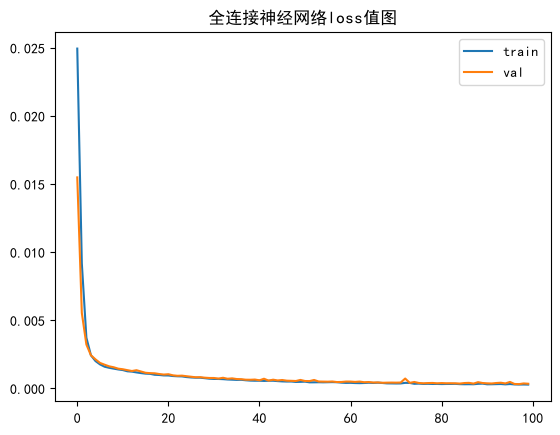

In [10]:

# 绘制模型的训练和验证集的loss值对比图
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')

plt.title("全连接神经网络loss值图")
plt.legend() # 显示图例（右上角的 train 和 val）
plt.show()

### 模型测试

In [11]:
import numpy as np

# ==========================================
# 1. 在测试集上进行最终评估（打分）
# ==========================================
# 评估模型在没见过的测试集上的 Loss 和 MAE（这里的数值是归一化后的尺度）
test_loss, test_mae = model.evaluate(X_test_scaled, Y_test_scaled, verbose=0)

print("=" * 40)
print(f"最终测试集成绩：")
print(f"测试集 Loss (MSE): {test_loss:.6f}")
print(f"测试集 MAE (平均绝对误差): {test_mae:.6f}")
print("=" * 40)

# ==========================================
# 2. 进行预测，并还原真实数值（关键！）
# ==========================================
# 模型对测试集进行预测（结果在 0~1 之间）
Y_pred_scaled = model.predict(X_test_scaled)

# 使用之前保存的标签归一化器（假设你之前叫 scaler_Y）进行反归一化
# 还原成真实的数字（比如房价、温度等）
Y_pred_real = scaler_Y.inverse_transform(Y_pred_scaled)
Y_test_real = scaler_Y.inverse_transform(Y_test_scaled.reshape(-1, 1))

# ==========================================
# 3. 抽取前 10 个样本，对比“真实值”与“预测值”
# ==========================================
print("\n--- 真实值与预测值对比（前 10 个样本） ---")
print(f"{'真实值':<15} | {'模型预测值':<15} | {'绝对误差':<15}")
print("-" * 50)

for i in range(10):
    true_val = Y_test_real[i][0]
    pred_val = Y_pred_real[i][0]
    error = abs(true_val - pred_val)

    print(f"{true_val:<17.4f} | {pred_val:<17.4f} | {error:<15.4f}")

最终测试集成绩：
测试集 Loss (MSE): 0.000297
测试集 MAE (平均绝对误差): 0.008921
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 

--- 真实值与预测值对比（前 10 个样本） ---
真实值             | 模型预测值           | 绝对误差           
--------------------------------------------------
191.0000          | 185.2208          | 5.7792         
263.0000          | 258.9497          | 4.0503         
272.0000          | 276.5553          | 4.5553         
79.0000           | 78.7438           | 0.2562         
158.0000          | 158.8939          | 0.8939         
106.0000          | 106.6943          | 0.6943         
144.0000          | 144.2684          | 0.2684         
396.0000          | 366.5736          | 29.4264        
69.0000           | 71.2776           | 2.2776         
73.0000           | 75.3815           | 2.3815         
